# MOP 3231 · Task 3 — Midterm Project
Bank Marketing: predict which clients will say "yes" to a term deposit.

## Setup


In [1]:
import sys, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, joblib
warnings.filterwarnings("ignore")

SEED = 3113
print("python", sys.version.split()[0], "| sklearn", sklearn.__version__,
      "| pandas", pd.__version__, "| numpy", np.__version__, "| SEED", SEED)

python 3.13.1 | sklearn 1.7.2 | pandas 2.3.3 | numpy 2.3.4 | SEED 3113


## Loading the dataset

In [2]:
train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")

print("train shape:", train.shape)
print("test shape :", test.shape)
train.head()

train shape: (32940, 22)
test shape : (8236, 20)


,id,age,job,marital,education,default,housing,loan,contact,month,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,0,39,management,single,basic.9y,unknown,yes,no,telephone,may,...,3,999,0,nonexistent,1.1,93.994,-36.4,4.856,5191.0,no
1,1,32,admin.,single,university.degree,no,yes,no,cellular,aug,...,2,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
2,2,41,technician,married,high.school,no,no,yes,cellular,aug,...,1,999,0,nonexistent,1.4,93.444,-36.1,4.963,5228.1,no
3,3,39,admin.,married,professional.course,no,yes,yes,telephone,may,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,4,51,blue-collar,married,basic.9y,unknown,no,no,telephone,jun,...,1,999,0,nonexistent,1.4,94.465,-41.8,4.864,5228.1,no


In [3]:
only_in_train = set(train.columns) - set(test.columns)
only_in_test = set(test.columns) - set(train.columns)

print("Only in train:", only_in_train)
print("Only in test :", only_in_test)

Only in train: {'y', 'duration'}
Only in test : set()


In [4]:
# target: "yes" -> 1, "no" -> 0
if train["y"].dtype == "object":
    train["y"] = train["y"].map({"yes": 1, "no": 0})

# features = all columns of test.csv except id
feature_cols = [c for c in test.columns if c != "id"]

X = train[feature_cols].copy()
y = train["y"].copy()

print("Number of features:", len(feature_cols))
print(feature_cols)

Number of features: 19
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


## Stage 1. Framing the problem

**Task.** The bank can call only 10% of clients in one campaign wave. The model gives every
client a score. The 10% of clients with the highest scores will get a call, so they should be
the clients who are most likely to say "yes" to a term deposit.

**Metric.** No need to use accuracy. Only about 11% of clients say "yes", so a model that always
says "no" already has about 89% accuracy but finds nobody.



## 2. Understanding the data

In [5]:
print(y.value_counts())

yes_rate = y.mean()
print("Share of yes:", round(yes_rate * 100, 1), "%")
print("Accuracy of a model that always says no:", round((1 - yes_rate) * 100, 1), "%")

y
0    29229
1     3711
Name: count, dtype: int64
Share of yes: 11.3 %
Accuracy of a model that always says no: 88.7 %


There are 32,940 clients in the training data. Only 3,711 of them (11.3%) said
"yes", and 29,229 said "no". A model that always answers "no" gets 88.7% accuracy, but it finds
zero clients who will say "yes". So accuracy is a bad metric here and can be misleading.

In [6]:
text_cols = X.select_dtypes(include="object").columns

for col in text_cols:
    n_unknown = (X[col] == "unknown").sum()
    if n_unknown > 0:
        print(col, ":", n_unknown, "unknown values")

if "pdays" in X.columns:
    n_999 = (X["pdays"] == 999).sum()
    print("pdays = 999:", n_999, "rows (", round(n_999 / len(X) * 100, 1), "% )")

job : 275 unknown values
marital : 64 unknown values
education : 1401 unknown values
default : 6871 unknown values
housing : 794 unknown values
loan : 794 unknown values
pdays = 999: 31694 rows ( 96.2 % )


In `pdays` the number 999 does not mean 999 days. It means "the client was not contacted in a
previous campaign". It appears in 31,694 rows (96.2%). So `pdays` is a special case: most clients have
this value.

In [7]:
changes = (X["month"] != X["month"].shift()).sum()
print("Month changes:", changes, "times in", len(X), "rows")

Month changes: 26442 times in 32940 rows


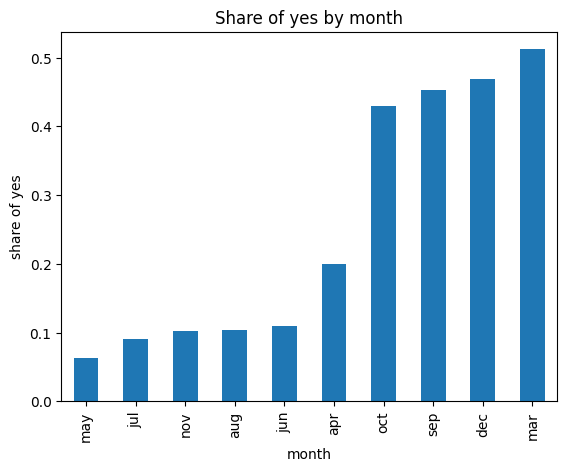

month
may    0.064
jul    0.091
nov    0.103
aug    0.104
jun    0.110
apr    0.200
oct    0.429
sep    0.453
dec    0.469
mar    0.512
Name: y, dtype: float64


In [ ]:
#graph1
month_rate = y.groupby(X["month"]).mean().sort_values()

month_rate.plot(kind="bar", title="Share of yes by month")
plt.ylabel("share of yes")
plt.show()

print(month_rate.round(3))

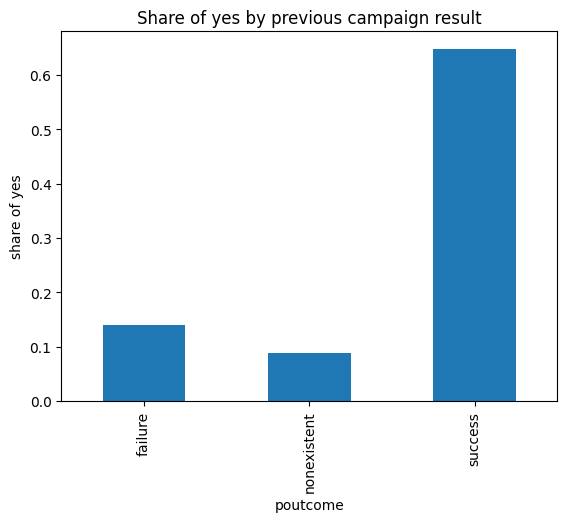

poutcome
failure        0.140
nonexistent    0.088
success        0.648
Name: y, dtype: float64


In [9]:
#graph2
poutcome_rate = y.groupby(X["poutcome"]).mean()

poutcome_rate.plot(kind="bar", title="Share of yes by previous campaign result")
plt.ylabel("share of yes")
plt.show()

print(poutcome_rate.round(3))

In [10]:
from sklearn.metrics import roc_auc_score

num_cols = X.select_dtypes(include="number").columns

rows = []
for col in num_cols:
    auc = roc_auc_score(y, X[col])
    strength = abs(auc - 0.5)   # 0 = no link, bigger = stronger link
    rows.append((col, round(auc, 3), round(strength, 3)))

table = pd.DataFrame(rows, columns=["feature", "auc", "strength"])
table.sort_values("strength", ascending=False)

,feature,auc,strength
8,nr.employed,0.250,0.250
7,euribor3m,0.255,0.245
4,emp.var.rate,0.283,0.217
3,previous,0.610,0.110
5,cons.price.idx,0.391,0.109
2,pdays,0.401,0.099
1,campaign,0.447,0.053
6,cons.conf.idx,0.542,0.042
0,age,0.491,0.009


 AUC = 0.5 means no
link with the answer. The farther from 0.5, the stronger the link. AUC below 0.5 means that
a higher value gives a lower chance of "yes".
- The strongest features are `nr.employed` (AUC 0.250), `euribor3m` (0.255) and
  `emp.var.rate` (0.283). They are economic indicators, and the link is negative: when they are
  high, fewer clients say "yes".
- `previous` (0.610), `cons.price.idx` (0.391) and `pdays` (0.401) have a weaker link.
- `campaign` (0.447), `cons.conf.idx` (0.542) and `age` (0.491) are close to 0.5, so each of
  them alone says very little.